[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/04-machine-learning/07_ensembles.ipynb)

*Machine Learning from Scratch · Notebook 7 of 10*

# Ensembles: Bagging, Forests & Boosting

Many models beat one: voting, bootstrap samples and bagging, random forests from the inside, gradient boosting built from scratch, AdaBoost's weights, and why averaging reduces variance.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Bagging is a committee voting independently. Boosting is a line of students each fixing the last one's mistakes.

**What interviewers really test here:** Bias vs variance, random forest vs gradient boosting, and when each wins.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. The wisdom of crowds *(Basics)*
- [ ] 2. Why voting works, with numbers *(Basics)*
- [ ] 3. Bagging and random forests *(Core)*
- [ ] 4. Gradient boosting: fixing mistakes one tree at a time *(Core)*
- [ ] 5. Bootstrap and out-of-bag, by hand *(Core)*
- [ ] 6. Random forests in depth *(Core)*
- [ ] 7. Gradient boosting, by hand *(Core)*
- [ ] 8. AdaBoost and stacking *(Advanced)*
- [ ] 9. Tuning boosting, and XGBoost / LightGBM *(Advanced)*
- [ ] 10. AdaBoost by hand, and picking an ensemble *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Ensemble families

| Method | Idea | sklearn |
| --- | --- | --- |
| Voting | combine different models by majority or averaged probabilities | VotingClassifier / VotingRegressor |
| Bagging | same model on bootstrap samples, averaged | BaggingClassifier / Regressor |
| Random forest | bagged trees + random feature subsets per split | RandomForestClassifier / Regressor |
| Extra trees | random thresholds too — even less correlated | ExtraTreesClassifier |
| AdaBoost | reweight misclassified samples sequentially | AdaBoostClassifier |
| Gradient boosting | fit each new tree to the negative gradient of the loss | GradientBoosting\*, HistGradientBoosting\* |
| Stacking | meta-model on out-of-fold base predictions | StackingClassifier / Regressor |

### Random forests

- Each tree: bootstrap sample of size n; at each split, consider max\_features random features ('sqrt' default for classification, 1.0 for regression in recent sklearn).
- P(a row is out of bag) = (1 − 1/n)ⁿ → e⁻¹ ≈ 0.368. OOB predictions give a validation estimate without a separate split (`oob_score=True`).
- Variance of the average: ρσ² + (1 − ρ)σ²/B. More trees never overfit (only plateau); feature subsampling lowers ρ.
- Classifier prediction = average of tree probabilities (not a hard vote).
- Key hyper-parameters: n\_estimators, max\_features, max\_depth / min\_samples\_leaf, class\_weight.

### Gradient boosting

F₀(x) = argmin\_c Σ L(yᵢ, c) (the mean for squared error). For m = 1 … M: pseudo-residuals rᵢ = −∂L/∂F(xᵢ); fit a regression tree hₘ to r; set leaf values by a line search (Newton step for log-loss); Fₘ = Fₘ₋₁ + η·hₘ.



| Loss | Pseudo-residual |
| --- | --- |
| Squared error | y − F |
| Absolute error | sign(y − F) |
| Log-loss | y − σ(F) |



Regularisation: learning rate η, n\_estimators with early stopping, max\_depth / max\_leaf\_nodes, subsample &lt; 1 (stochastic boosting), min\_samples\_leaf, L2 on leaf values (XGBoost). Modern libraries bin features into histograms for speed and handle missing values and categories natively.

### AdaBoost (SAMME)

1. Initialise weights wᵢ = 1/n.
2. Fit a weak learner with weights; err = Σ wᵢ[yᵢ ≠ ŷᵢ] / Σ wᵢ.
3. α = ln((1 − err)/err) + ln(K − 1).
4. wᵢ ← wᵢ·e^α for misclassified rows; normalise.
5. Predict by the α-weighted vote. Binary AdaBoost minimises the exponential loss e^(−y·F(x)).

### Random forest vs gradient boosting

|   | Random forest | Gradient boosting |
| --- | --- | --- |
| Trees | deep, independent, parallel | shallow, sequential |
| Reduces | variance | bias (then variance through shrinkage) |
| More trees | never overfits, only plateaus | can overfit; use early stopping |
| Tuning effort | low | higher, but usually higher accuracy |
| Noisy labels | robust | more sensitive |
| Training | easy to parallelise | sequential across trees |

---
# Part 2: Lessons, step by step

## Lesson 1: The wisdom of crowds

*Level: Basics*

One deep decision tree overfits: change a few rows and it changes completely (high **variance**). Average many different models and their individual mistakes cancel out. That's an **ensemble**.




- **Voting**: train different models (logistic regression, a tree, k-NN) and let them vote (**hard**) or average their probabilities (**soft**).
- Averaging k models with error variance σ² and correlation ρ gives variance ρσ² + (1 − ρ)σ²/k: it only helps if the models are **different** (low ρ).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

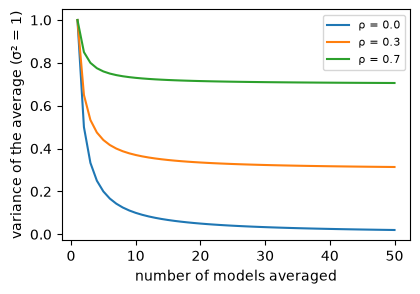

In [2]:
def variance_curve():
    k = np.arange(1, 51)
    fig, ax = plt.subplots(figsize=(4.5, 3))
    for rho in [0.0, 0.3, 0.7]:
        ax.plot(k, rho + (1 - rho) / k, label=f"ρ = {rho}")
    ax.set_xlabel("number of models averaged")
    ax.set_ylabel("variance of the average (σ² = 1)")
    ax.legend(fontsize=8)


variance_curve()

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q9](#q9), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 2: Why voting works, with numbers

*Level: Basics*

Suppose several models are each right 70% of the time and **make independent mistakes**. A majority vote is right when more than half are right.



#### Worked example: three models



- All three right: 0.7³ = 0.343
- Exactly two right: 3 × 0.7² × 0.3 = 0.441
- Majority right: 0.343 + 0.441 = **0.784**



| Models | 1 | 3 | 5 | 11 |
| --- | --- | --- | --- | --- |
| Vote accuracy | 0.700 | 0.784 | 0.837 | 0.922 |



**The catch is "independent".** If all models make the same mistakes, voting changes nothing. So ensembles need **diversity**: different data samples, features or algorithms. And each model must beat chance, since voting among models worse than 50% makes things worse.



**Hard or soft voting?** Hard counts class votes. Soft averages probabilities, which respects each model's confidence and usually works better when probabilities are reasonable.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

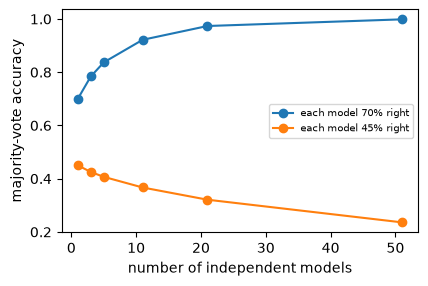

In [3]:
import math


def vote_math():
    def vote_accuracy(n, p=0.7):
        return sum(math.comb(n, k) * p ** k * (1 - p) ** (n - k) for k in range(n // 2 + 1, n + 1))

    sizes = [1, 3, 5, 11, 21, 51]
    good = [vote_accuracy(n) for n in sizes]
    bad = [vote_accuracy(n, 0.45) for n in sizes]
    fig, ax = plt.subplots(figsize=(4.6, 2.9))
    ax.plot(sizes, good, "o-", label="each model 70% right")
    ax.plot(sizes, bad, "o-", label="each model 45% right")
    ax.set_xlabel("number of independent models")
    ax.set_ylabel("majority-vote accuracy")
    ax.legend(fontsize=7)


vote_math()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. vote\_accuracy() returns 0.7
2. vote\_accuracy() returns 0.7839999999999999
3. vote\_accuracy() returns 0.8369199999999999
4. vote\_accuracy() returns 0.92177520904
5. vote\_accuracy() returns 0.973610059298716
6. vote\_accuracy() returns 0.9986359101260261
7. vote\_accuracy() returns 0.45
8. vote\_accuracy() returns 0.4252500000000001

</details>


**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q9](#q9), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 3: Bagging and random forests

*Level: Core*

**Bagging** (bootstrap aggregating): train each model on a **bootstrap sample** — n rows drawn *with replacement*, so some rows repeat and about 37% are left out. Average (regression) or vote (classification).



A **random forest** = bagging of deep trees + at every split, only a **random subset of features** is considered (√d for classification). This decorrelates the trees, so averaging removes much more variance.




- The left-out rows are free validation data: the **out-of-bag (OOB) score**.
- Few hyper-parameters, robust defaults, no scaling, gives feature importances — a superb first model for tabular data.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

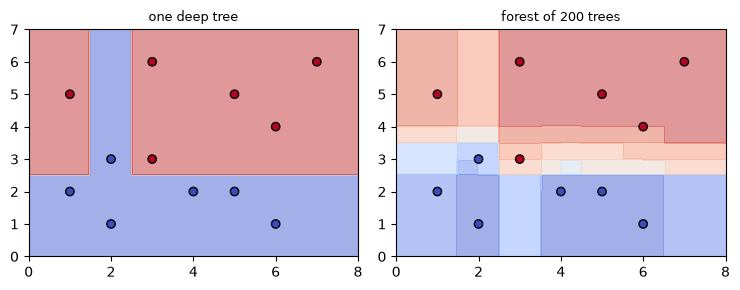

In [4]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor
from sklearn.tree import DecisionTreeClassifier
X = np.array([[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6], [6, 1], [1, 5]], dtype=float)
Y = np.array([0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1])


def tree_vs_forest():
    xx, yy = np.meshgrid(np.linspace(0, 8, 150), np.linspace(0, 7, 150))
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    models = [("one deep tree", DecisionTreeClassifier(random_state=0)),
              ("forest of 200 trees", RandomForestClassifier(n_estimators=200, random_state=0))]
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3))
    for ax, (name, model) in zip(axes, models):
        prob = model.fit(X, Y).predict_proba(grid)[:, 1].reshape(xx.shape)
        ax.contourf(xx, yy, prob, levels=10, cmap="coolwarm", alpha=0.5)
        ax.scatter(X[:, 0], X[:, 1], c=Y, cmap="coolwarm", edgecolor="black")
        ax.set_title(name, fontsize=9)
    fig.tight_layout()


tree_vs_forest()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q3](#q3), [Q10](#q10), [Q4](#q4), [Q11](#q11), [Q12](#q12), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 4: Gradient boosting: fixing mistakes one tree at a time

*Level: Core*

**Boosting** builds the ensemble **sequentially**. Gradient boosting for regression:




1. Start with a constant prediction: the mean of y.
2. Compute the **residuals** (what's still wrong).
3. Fit a small tree to the residuals.
4. Add it, scaled down by the **learning rate**: prediction += lr × tree.
5. Repeat for n\_estimators rounds.



Residuals are the negative gradient of squared error — swap in other losses' gradients for classification or ranking. Small learning rate + many trees + shallow trees (depth 3–8) generalises best; stop early when validation error rises. XGBoost, LightGBM, CatBoost and sklearn's HistGradientBoosting are fast versions — the usual winners on tabular data.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

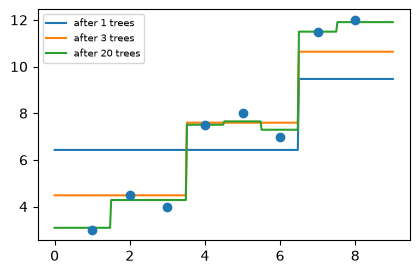

In [5]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor


def boosting_stages():
    x = np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float).reshape(-1, 1)
    y = np.array([3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0])
    grid = np.linspace(0, 9, 300).reshape(-1, 1)
    gb = GradientBoostingRegressor(n_estimators=20, learning_rate=0.5, max_depth=1, random_state=0).fit(x, y)
    stages = list(gb.staged_predict(grid))
    fig, ax = plt.subplots(figsize=(4.8, 3))
    ax.scatter(x, y, zorder=3)
    for i in [0, 2, 19]:
        ax.plot(grid, stages[i], label=f"after {i + 1} trees")
    ax.legend(fontsize=7)


boosting_stages()

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q13](#q13), [Q19](#q19), [Q14](#q14), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 5: Bootstrap and out-of-bag, by hand

*Level: Core*

A **bootstrap sample** draws n rows **with replacement** from n rows. From rows 0–7 you might get 0, 3, 3, 1, 7, 0, 5, 3. Rows 0 and 3 repeat, while rows 2, 4 and 6 were never picked.



#### Why about 37% get left out



On a single draw, a given row is missed with probability 1 − 1/n. Over n draws it's missed with probability (1 − 1/n)ⁿ.



| n | 10 | 1000 | very large |
| --- | --- | --- | --- |
| Left out | 0.349 | 0.368 | 1/e ≈ 0.368 |



So each tree sees about 63% of the unique rows.



#### The out-of-bag (OOB) score



1. For row 2, find the trees that never saw it (about 37% of them).
2. Let only those trees predict it.
3. Do this for every row and measure accuracy.



That's a validation score without setting any data aside, and it often closely tracks cross-validation. The demo compares them while adding trees.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

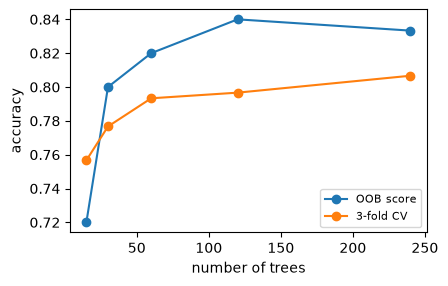

In [6]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor


def oob_curve():
    from sklearn.model_selection import cross_val_score
    rng = np.random.default_rng(0)
    data = rng.normal(size=(300, 6))
    target = (data[:, 0] + data[:, 1] * data[:, 2] + rng.normal(0, 0.5, 300) > 0).astype(int)
    sizes = [15, 30, 60, 120, 240]
    oob = [RandomForestClassifier(n_estimators=n, oob_score=True, random_state=0).fit(data, target).oob_score_ for n in sizes]
    cv = [cross_val_score(RandomForestClassifier(n_estimators=n, random_state=0), data, target, cv=3).mean() for n in sizes]
    fig, ax = plt.subplots(figsize=(4.6, 2.9))
    ax.plot(sizes, oob, "o-", label="OOB score")
    ax.plot(sizes, cv, "o-", label="3-fold CV")
    ax.set_xlabel("number of trees")
    ax.set_ylabel("accuracy")
    ax.legend(fontsize=8)


oob_curve()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 6: Random forests in depth

*Level: Core*

#### The algorithm



1. Draw a bootstrap sample.
2. Grow a deep tree. At each split, consider only a random subset of features, and pick the best split among them.
3. Repeat for every tree.
4. Predict by averaging probabilities (classification) or values (regression).



#### Why random features matter



If one feature is very strong, every tree would start with it, the trees would look alike, and averaging would achieve little. Hiding it from some splits forces trees to find other patterns. From the variance formula ρσ² + (1 − ρ)σ²/k, lowering the correlation ρ is what breaks the floor that more trees alone can't.



#### Tuning guide



| Setting | Advice |
| --- | --- |
| n\_estimators | more is never harmful, just slower; 200–500 is usual |
| max\_features | the most important: 'sqrt' to start, then try a few values |
| min\_samples\_leaf | raise it (2–10) for noisy data, smoother probabilities |
| max\_depth | often unlimited; limit it to save memory |
| class\_weight | "balanced" for rare classes |



**Limits:** can't extrapolate, large models, slower prediction, and importances suffer with correlated features.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

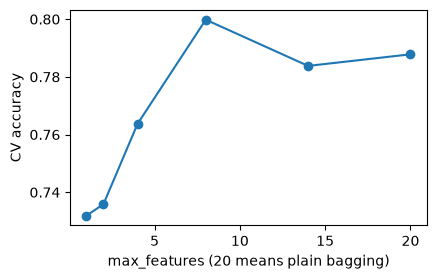

In [7]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor


def max_features_effect():
    from sklearn.model_selection import cross_val_score
    rng = np.random.default_rng(1)
    data = rng.normal(size=(250, 20))
    target = (data[:, :4].sum(axis=1) + rng.normal(0, 1, 250) > 0).astype(int)
    choices = [1, 2, 4, 8, 14, 20]
    scores = [cross_val_score(RandomForestClassifier(n_estimators=60, max_features=m, random_state=0), data, target, cv=3).mean() for m in choices]
    fig, ax = plt.subplots(figsize=(4.6, 2.8))
    ax.plot(choices, scores, "o-")
    ax.set_xlabel("max_features (20 means plain bagging)")
    ax.set_ylabel("CV accuracy")


max_features_effect()

**✏️ Your turn:** you now have what you need for [Q10](#q10), [Q4](#q4), [Q11](#q11), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 7: Gradient boosting, by hand

*Level: Core*

Data: x = 1, 2, 3, 4 and y = 2, 4, 7, 11. Learning rate 0.5, with stumps (one split each).



#### Start: predict the mean, 6



| Round | Current prediction | Residuals the tree must learn | Stump found | MSE after |
| --- | --- | --- | --- | --- |
| 1 | 6, 6, 6, 6 | −4, −2, 1, 5 | x ≤ 2.5 → −3, else +3 | 4.75 |
| 2 | 4.5, 4.5, 7.5, 7.5 | −2.5, −0.5, −0.5, 3.5 | x ≤ 3.5 → −1.167, else +3.5 | 1.69 |
| 3 | 3.92, 3.92, 6.92, 9.25 | −1.92, 0.08, 0.08, 1.75 | x ≤ 1.5 → −1.92, else +0.64 | 0.77 |



Check round 1: for x = 1, the new prediction is 6 + 0.5 × (−3) = 4.5.



After three rounds the predictions are 2.96, 4.24, 7.24, 9.57, against true values of 2, 4, 7, 11. Each tree works on **what's still wrong**.



#### Why "gradient"?



For squared error L = ½(y − F)², the slope with respect to the prediction is −(y − F). So the residual is exactly the negative gradient, and adding a tree that fits residuals is one step of gradient descent, taken in the space of predictions. Other losses just change what the trees fit. For log-loss, they fit y − p.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [8]:
def boosting_by_hand():
    x = np.array([1.0, 2, 3, 4])
    y = np.array([2.0, 4, 7, 11])
    pred = np.full(4, y.mean())
    history = []
    for round_number in range(3):
        residuals = y - pred
        best = None
        for t in (x[:-1] + x[1:]) / 2:
            left, right = residuals[x <= t], residuals[x > t]
            error = ((left - left.mean()) ** 2).sum() + ((right - right.mean()) ** 2).sum()
            if best is None or error < best[0] - 1e-12:
                best = (error, t, left.mean(), right.mean())
        pred = pred + 0.5 * np.where(x <= best[1], best[2], best[3])
        history.append(((y - pred) ** 2).mean())


boosting_by_hand()

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q13](#q13), [Q19](#q19), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 8: AdaBoost and stacking

*Level: Advanced*

**AdaBoost** (the original boosting): train a weak learner (a stump), measure its **weighted error**, give it a say α = ln((1 − err)/err), then **increase the weights of the rows it got wrong** so the next learner focuses on them. The final prediction is an α-weighted vote.



**Stacking**: train several different models, then train a **meta-model** on their (out-of-fold) predictions to learn how much to trust each.



|   | Bagging / forests | Boosting |
| --- | --- | --- |
| Builds models | in parallel, independently | in sequence, each fixing the last |
| Mainly reduces | variance | bias (and variance with shrinkage) |
| Base models | deep trees | shallow trees |
| Overfitting risk | low | higher — tune lr, depth, rounds |

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

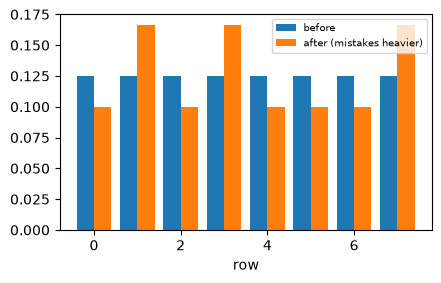

In [9]:
import math


def adaboost_weights():
    y = np.array([1, 0, 1, 1, 0, 1, 0, 0])
    pred = np.array([1, 1, 1, 0, 0, 1, 0, 1])
    w = np.full(len(y), 1 / len(y))
    err = w[y != pred].sum()
    alpha = math.log((1 - err) / err)
    new_w = w * np.where(y != pred, math.exp(alpha), 1.0)
    new_w = new_w / new_w.sum()
    fig, ax = plt.subplots(figsize=(4.8, 2.8))
    ax.bar(np.arange(len(y)) - 0.2, w, width=0.4, label="before")
    ax.bar(np.arange(len(y)) + 0.2, new_w, width=0.4, label="after (mistakes heavier)")
    ax.set_xlabel("row")
    ax.legend(fontsize=7)


adaboost_weights()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q16](#q16), [Q17](#q17), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 9: Tuning boosting, and XGBoost / LightGBM

*Level: Advanced*

#### The settings that matter



| Setting | Effect | Typical |
| --- | --- | --- |
| learning\_rate + n\_estimators | small steps need more trees, and generalise better | 0.01–0.1, with early stopping |
| max\_depth | how many features can interact | 3–8 |
| subsample | each tree sees a random share of rows | 0.5–0.9 |
| colsample | random share of features | 0.5–0.9 |
| min\_samples\_leaf, L2 | smoother, safer leaf values | tune last |



#### Recipe



1. Fix a small learning rate and use early stopping to find the number of trees.
2. Tune depth, then row and feature sampling.
3. Lower the rate further at the end.



#### Unlike a forest, boosting can overfit with more trees



The demo shows training error always falling, while test error reaches a minimum and rises. Early stopping halts at that minimum.



#### The popular libraries



| Library | Known for |
| --- | --- |
| XGBoost | regularised objective using second derivatives |
| LightGBM | histogram-based, leaf-wise growth, very fast |
| CatBoost | strong native handling of categories |
| sklearn HistGradientBoosting | no extra install, handles missing values |

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

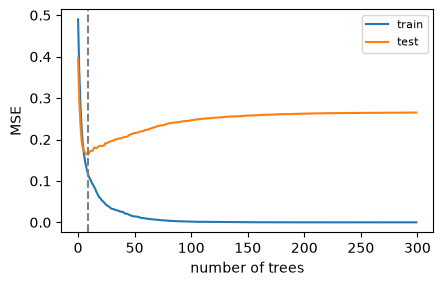

In [10]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor


def boosting_overfit():
    rng = np.random.default_rng(0)
    x = rng.uniform(0, 10, (200, 1))
    y = np.sin(x.ravel()) + rng.normal(0, 0.4, 200)
    gb = GradientBoostingRegressor(n_estimators=300, learning_rate=0.2, max_depth=4, random_state=0).fit(x[:120], y[:120])
    train_error = [((p - y[:120]) ** 2).mean() for p in gb.staged_predict(x[:120])]
    test_error = [((p - y[120:]) ** 2).mean() for p in gb.staged_predict(x[120:])]
    best_round = int(np.argmin(test_error))
    fig, ax = plt.subplots(figsize=(4.8, 2.9))
    ax.plot(train_error, label="train")
    ax.plot(test_error, label="test")
    ax.axvline(best_round, ls="--", color="gray")
    ax.set_xlabel("number of trees")
    ax.set_ylabel("MSE")
    ax.legend(fontsize=8)


boosting_overfit()

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 10: AdaBoost by hand, and picking an ensemble

*Level: Advanced*

#### One AdaBoost round



Five rows start with weights of 0.2 each, and a stump gets 2 of them wrong.



1. Weighted error = 0.2 + 0.2 = **0.4**.
2. The model's say: α = ln(0.6 / 0.4) = **0.405**. Better models get a larger say; at 50% error, α = 0.
3. Multiply the wrong rows' weights by e^α = 1.5: they become 0.3.
4. The total is now 3 × 0.2 + 2 × 0.3 = 1.2. Divide: right rows become **0.167** and wrong rows **0.25**.



The wrong rows now hold half the total weight (0.25 × 2 = 0.5), so the next stump must focus on them. Because it chases hard rows, AdaBoost is sensitive to noisy labels.



#### Which ensemble?



| Situation | Choose |
| --- | --- |
| Quick, strong result with little tuning | random forest |
| Highest accuracy on tables, time to tune | gradient boosting |
| Very noisy labels | random forest |
| Several good, different models | soft voting or stacking |



**Stacking warning:** train the meta-model on **out-of-fold** predictions. Using predictions on the base models' own training rows makes it trust whichever model overfit most.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

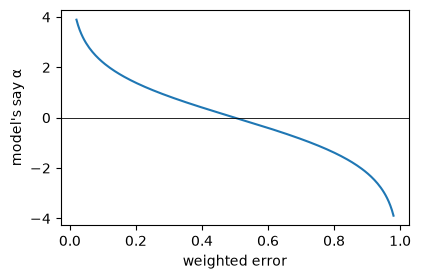

In [11]:
def alpha_curve():
    err = np.linspace(0.02, 0.98, 200)
    alpha = np.log((1 - err) / err)
    weights_after = np.array([0.2, 0.2, 0.2, 0.2 * 1.5, 0.2 * 1.5])
    weights_after = weights_after / weights_after.sum()
    fig, ax = plt.subplots(figsize=(4.5, 2.8))
    ax.plot(err, alpha)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_xlabel("weighted error")
    ax.set_ylabel("model's say α")


alpha_curve()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q16](#q16), [Q17](#q17), [Q20](#q20). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [12]:
from sklearn.ensemble import (VotingClassifier, RandomForestClassifier, BaggingRegressor,
                              GradientBoostingRegressor)

X = [[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6]]

import math

from sklearn.linear_model import LogisticRegression, LinearRegression

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

from sklearn.neighbors import KNeighborsClassifier


<a id="q1"></a>
### Q1. A Bootstrap Sample

🟢 Warm-up · *Sampling with replacement*

Draw n row indices with replacement using np.random.RandomState(seed).randint(0, n, n).

**Examples**

- `n = 8, seed = 0` → `[4, 7, 5, 0, 3, 3, 3, 7]`
- `n = 5, seed = 42` → `[3, 4, 2, 4, 4]`

In [ ]:
from sklearn.utils import resample

def bootstrap(n, seed):
    """
    Draw n row indices with replacement using
    np.random.RandomState(seed).randint(0, n, n).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bootstrap, [
    ((8, 0), [4, 7, 5, 0, 3, 3, 3, 7]),
    ((5, 42), [3, 4, 2, 4, 4]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A seeded random generator, one randint call.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sklearn.utils.resample(range(n), random_state=seed)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** A seeded random generator, one randint call.

```python
def bootstrap(n, seed):
    rng = np.random.RandomState(seed)
    return rng.randint(0, n, n)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `sklearn.utils.resample(range(n), random_state=seed)`.

```python
def bootstrap(n, seed):
    return resample(np.arange(n), random_state=seed)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A seeded random generator, one randint call. That costs O(n) time and O(n) space."

"I can do better: `sklearn.utils.resample(range(n), random_state=seed)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/a-bootstrap-sample)

<a id="q2"></a>
### Q2. Out-of-Bag Rows

🟢 Warm-up · *Free validation data*

Given the indices of a bootstrap sample of n rows, return the rows that were never picked (sorted).

**Examples**

- `sample = [0, 3, 3, 1, 7, 0, 5, 3], n = 8` → `[2, 4, 6]`
- `sample = [2, 2, 2], n = 3` → `[0, 1]`

In [ ]:
def out_of_bag(sample, n):
    """
    Given the indices of a bootstrap sample of n rows, return the rows that were
    never picked (sorted).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(out_of_bag, [
    (([0, 3, 3, 1, 7, 0, 5, 3], 8), [2, 4, 6]),
    (([2, 2, 2], 3), [0, 1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Mark the picked rows, list the rest.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.setdiff1d(np.arange(n), sample)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Mark the picked rows, list the rest.

```python
def out_of_bag(sample, n):
    picked = set(sample)
    return [i for i in range(n) if i not in picked]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `np.setdiff1d(np.arange(n), sample)`.

```python
def out_of_bag(sample, n):
    return np.setdiff1d(np.arange(n), sample)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Mark the picked rows, list the rest. That costs O(n) time and O(n) space."

"I can do better: `np.setdiff1d(np.arange(n), sample)`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/out-of-bag-rows)

<a id="q3"></a>
### Q3. Chance a Row Is Left Out

🟢 Warm-up · *≈ 1/e ≈ 36.8%*

Return the probability that a given row is not in a bootstrap sample of size n, rounded to 4 decimals.

**Examples**

- `n = 10` → `0.3487`
- `n = 1000` → `0.3677`

In [ ]:
def left_out(n):
    """
    Return the probability that a given row is not in a bootstrap sample of size
    n, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(left_out, [
    ((10,), 0.3487),
    ((1000,), 0.3677),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Each of the n draws misses it with probability (1 − 1/n); multiply n times.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formula (1 − 1/n)ⁿ, which tends to e⁻¹.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Each of the n draws misses it with probability (1 − 1/n); multiply n times.

```python
def left_out(n):
    p = 1.0
    for _ in range(n):
        p *= 1 - 1 / n
    return round(p, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Formula (1 − 1/n)ⁿ, which tends to e⁻¹.

```python
def left_out(n):
    return round((1 - 1 / n) ** n, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Each of the n draws misses it with probability (1 − 1/n); multiply n times. That costs O(n) time and O(1) space."

"I can do better: Formula (1 − 1/n)ⁿ, which tends to e⁻¹. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/chance-a-row-is-left-out)

<a id="q4"></a>
### Q4. Count the Trees' Votes

🟢 Warm-up · *How confident is the forest?*

Fit RandomForestClassifier(n\_estimators=7, random\_state=0) and return, for each query, how many trees vote class 1.

**Examples**

- `X = [[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6]], y = [0, 0, 1, 0, 1, 1, 0, 0, 1, 1], queries = [[1, 1], [4, 4], [6, 6], [3, 2], [5, 3]]` → `[0, 6, 7, 0, 4]`

In [ ]:
def tree_votes(X, y, queries):
    """
    Fit RandomForestClassifier(n_estimators=7, random_state=0) and return, for
    each query, how many trees vote class 1.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(tree_votes, [
    (([[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6]], [0, 0, 1, 0, 1, 1, 0, 0, 1, 1], [[1, 1], [4, 4], [6, 6], [3, 2], [5, 3]]), [0, 6, 7, 0, 4]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ask every tree and count.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Stack all trees' predictions into a matrix and sum the columns.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Ask every tree and count.

```python
def tree_votes(X, y, queries):
    forest = RandomForestClassifier(n_estimators=7, random_state=0).fit(X, y)
    counts = [0] * len(queries)
    for tree in forest.estimators_:
        for i, p in enumerate(tree.predict(np.array(queries, dtype=float))):
            counts[i] += int(forest.classes_[int(p)] == 1)
    return counts
```

**Cost:** O(trees·m) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Stack all trees' predictions into a matrix and sum the columns.

```python
def tree_votes(X, y, queries):
    forest = RandomForestClassifier(n_estimators=7, random_state=0).fit(X, y)
    votes = np.array([t.predict(np.array(queries, dtype=float)) for t in forest.estimators_])
    return (forest.classes_[votes.astype(int)] == 1).sum(axis=0)
```

**Cost:** O(trees·m) time, O(trees·m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ask every tree and count. That costs O(trees·m) time and O(m) space."

"I can do better: Stack all trees' predictions into a matrix and sum the columns. That's O(trees·m) time and O(trees·m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/count-the-trees-votes)

<a id="q5"></a>
### Q5. Features Tried at Each Split

🟢 Warm-up · *max\_features*

A random forest with d features considers how many at each split for max\_features = 'sqrt' and 'log2'? Return (sqrt count, log2 count).

**Examples**

- `d = 16` → `(4, 4)`
- `d = 10` → `(3, 3)`

In [ ]:
def features_per_split(d):
    """
    A random forest with d features considers how many at each split for
    max_features = 'sqrt' and 'log2'? Return (sqrt count, log2 count).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(features_per_split, [
    ((16,), (4, 4)),
    ((10,), (3, 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

int(√d) and int(log₂ d), at least 1.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Fit tiny forests and read a tree's `max_features_`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** int(√d) and int(log₂ d), at least 1.

```python
def features_per_split(d):
    return (max(1, int(math.sqrt(d))), max(1, int(math.log2(d))))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Fit tiny forests and read a tree's `max_features_`.

```python
def features_per_split(d):
    Xd, yd = np.eye(d + 2)[:, :d], np.arange(d + 2) % 2
    a = RandomForestClassifier(n_estimators=1, max_features="sqrt", random_state=0).fit(Xd, yd)
    b = RandomForestClassifier(n_estimators=1, max_features="log2", random_state=0).fit(Xd, yd)
    return (a.estimators_[0].max_features_, b.estimators_[0].max_features_)
```

**Cost:** O(fit) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: int(√d) and int(log₂ d), at least 1. That costs O(1) time and O(1) space."

"I can do better: Fit tiny forests and read a tree's `max_features_`. That's O(fit) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/features-tried-at-each-split)

<a id="q6"></a>
### Q6. Boosting Starts From the Mean

🟢 Warm-up · *The initial guess*

Gradient boosting for squared error starts by predicting the mean of y. Return that value, rounded to 4 decimals.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0]` → `7.1875`

In [ ]:
def boost_init(X, y):
    """
    Gradient boosting for squared error starts by predicting the mean of y.
    Return that value, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(boost_init, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0]), 7.1875),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Average y.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`GradientBoostingRegressor().fit(X, y).init_.predict`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Average y.

```python
def boost_init(X, y):
    return round(sum(y) / len(y), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `GradientBoostingRegressor().fit(X, y).init_.predict`.

```python
def boost_init(X, y):
    gb = GradientBoostingRegressor(n_estimators=1, random_state=0).fit(X, y)
    return round(gb.init_.predict(np.array(X[:1], dtype=float))[0], 4)
```

**Cost:** O(fit) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Average y. That costs O(n) time and O(1) space."

"I can do better: `GradientBoostingRegressor().fit(X, y).init_.predict`. That's O(fit) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/boosting-starts-from-the-mean)

<a id="q7"></a>
### Q7. Weighted Error of a Weak Learner

🟢 Warm-up · *AdaBoost, step 1*

Return Σ wᵢ over misclassified rows divided by Σ wᵢ, rounded to 4 decimals.

**Examples**

- `y = [1, 0, 1, 1, 0], pred = [1, 1, 1, 0, 0], w = [0.1, 0.3, 0.2, 0.2, 0.2]` → `0.5`

In [ ]:
def weighted_error(y, pred, w):
    """
    Return Σ wᵢ over misclassified rows divided by Σ wᵢ, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(weighted_error, [
    (([1, 0, 1, 1, 0], [1, 1, 1, 0, 0], [0.1, 0.3, 0.2, 0.2, 0.2]), 0.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop adding the weights of the mistakes.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy: `w[y != pred].sum() / w.sum()`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop adding the weights of the mistakes.

```python
def weighted_error(y, pred, w):
    wrong = sum(wi for a, b, wi in zip(y, pred, w) if a != b)
    return round(wrong / sum(w), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** NumPy: `w[y != pred].sum() / w.sum()`.

```python
def weighted_error(y, pred, w):
    y, pred, w = np.array(y), np.array(pred), np.array(w)
    return round(w[y != pred].sum() / w.sum(), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop adding the weights of the mistakes. That costs O(n) time and O(1) space."

"I can do better: NumPy: `w[y != pred].sum() / w.sum()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/weighted-error-of-a-weak-learner)

<a id="q8"></a>
### Q8. Hard Voting by Hand

🟡 Interview standard · *Majority of three models*

Fit logistic regression, a depth-2 tree and 3-NN on (X, y); predict each query by majority vote.

**Examples**

- `X = [[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6]], y = [0, 0, 1, 0, 1, 1, 0, 0, 1, 1], queries = [[1, 1], [4, 4], [6, 6], [3, 2], [5, 3]]` → `[0, 1, 1, 0, 1]`

In [ ]:
def hard_vote(X, y, queries):
    """
    Fit logistic regression, a depth-2 tree and 3-NN on (X, y); predict each
    query by majority vote.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(hard_vote, [
    (([[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6]], [0, 0, 1, 0, 1, 1, 0, 0, 1, 1], [[1, 1], [4, 4], [6, 6], [3, 2], [5, 3]]), [0, 1, 1, 0, 1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Fit the three models separately and count their votes per query.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`VotingClassifier(..., voting='hard')`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Fit the three models separately and count their votes per query.

```python
def three_models():
    return [LogisticRegression(), DecisionTreeClassifier(max_depth=2, random_state=0), KNeighborsClassifier(n_neighbors=3)]


def hard_vote(X, y, queries):
    preds = [m.fit(X, y).predict(queries) for m in three_models()]
    out = []
    for i in range(len(queries)):
        votes = [int(p[i]) for p in preds]
        out.append(max(sorted(set(votes)), key=votes.count))
    return out
```

**Cost:** O(models·fit) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `VotingClassifier(..., voting='hard')`.

```python
def three_models():
    return [LogisticRegression(), DecisionTreeClassifier(max_depth=2, random_state=0), KNeighborsClassifier(n_neighbors=3)]


def hard_vote(X, y, queries):
    names = ["lr", "tree", "knn"]
    vote = VotingClassifier(list(zip(names, three_models())), voting="hard").fit(X, y)
    return vote.predict(queries)
```

**Cost:** O(models·fit) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Fit the three models separately and count their votes per query. That costs O(models·fit) time and O(m) space."

"I can do better: `VotingClassifier(..., voting='hard')`. That's O(models·fit) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/hard-voting-by-hand)

<a id="q9"></a>
### Q9. Soft Voting

🟡 Interview standard · *Average the probabilities*

Average the three models' P(class 1) for each query and return them, rounded to 4 decimals.

**Examples**

- `X = [[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6]], y = [0, 0, 1, 0, 1, 1, 0, 0, 1, 1], queries = [[1, 1], [4, 4], [6, 6], [3, 2], [5, 3]]` → `[0.0093, 0.7993, 0.9942, 0.1642, 0.6293]`

In [ ]:
def soft_vote(X, y, queries):
    """
    Average the three models' P(class 1) for each query and return them, rounded
    to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(soft_vote, [
    (([[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6]], [0, 0, 1, 0, 1, 1, 0, 0, 1, 1], [[1, 1], [4, 4], [6, 6], [3, 2], [5, 3]]), [0.0093, 0.7993, 0.9942, 0.1642, 0.6293]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Fit each model, average their predict\_proba columns by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`VotingClassifier(..., voting='soft').predict_proba`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Fit each model, average their predict\_proba columns by hand.

```python
def three_models():
    return [LogisticRegression(), DecisionTreeClassifier(max_depth=2, random_state=0), KNeighborsClassifier(n_neighbors=3)]


def soft_vote(X, y, queries):
    probs = [m.fit(X, y).predict_proba(queries)[:, 1] for m in three_models()]
    return [round(sum(p[i] for p in probs) / 3, 4) for i in range(len(queries))]
```

**Cost:** O(models·fit) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `VotingClassifier(..., voting='soft').predict_proba`.

```python
def three_models():
    return [LogisticRegression(), DecisionTreeClassifier(max_depth=2, random_state=0), KNeighborsClassifier(n_neighbors=3)]


def soft_vote(X, y, queries):
    vote = VotingClassifier(list(zip(["lr", "tree", "knn"], three_models())), voting="soft").fit(X, y)
    return vote.predict_proba(queries)[:, 1].round(4)
```

**Cost:** O(models·fit) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Fit each model, average their predict\_proba columns by hand. That costs O(models·fit) time and O(m) space."

"I can do better: `VotingClassifier(..., voting='soft').predict_proba`. That's O(models·fit) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/soft-voting)

<a id="q10"></a>
### Q10. Forest Probability = Average of Its Trees

🟡 Interview standard · *Inside a random forest*

Fit RandomForestClassifier(n\_estimators=5, random\_state=0) and return P(class 1) for each query, rounded to 4 decimals.

**Examples**

- `X = [[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6]], y = [0, 0, 1, 0, 1, 1, 0, 0, 1, 1], queries = [[1, 1], [4, 4], [6, 6], [3, 2], [5, 3]]` → `[0.0, 0.8, 1.0, 0.0, 0.4]`

In [ ]:
def forest_proba(X, y, queries):
    """
    Fit RandomForestClassifier(n_estimators=5, random_state=0) and return
    P(class 1) for each query, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(forest_proba, [
    (([[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6]], [0, 0, 1, 0, 1, 1, 0, 0, 1, 1], [[1, 1], [4, 4], [6, 6], [3, 2], [5, 3]]), [0.0, 0.8, 1.0, 0.0, 0.4]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over `forest.estimators_` and average each tree's probabilities yourself.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`forest.predict_proba`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop over `forest.estimators_` and average each tree's probabilities yourself.

```python
def forest_proba(X, y, queries):
    forest = RandomForestClassifier(n_estimators=5, random_state=0).fit(X, y)
    total = np.zeros(len(queries))
    for tree in forest.estimators_:
        total += tree.predict_proba(np.array(queries, dtype=float))[:, 1]
    return (total / len(forest.estimators_)).round(4)
```

**Cost:** O(trees·depth) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `forest.predict_proba`.

```python
def forest_proba(X, y, queries):
    forest = RandomForestClassifier(n_estimators=5, random_state=0).fit(X, y)
    return forest.predict_proba(queries)[:, 1].round(4)
```

**Cost:** O(trees·depth) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over `forest.estimators_` and average each tree's probabilities yourself. That costs O(trees·depth) time and O(m) space."

"I can do better: `forest.predict_proba`. That's O(trees·depth) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/forest-probability-average-of-its-trees)

<a id="q11"></a>
### Q11. Forest Feature Importances

🟡 Interview standard · *Averaged over trees*

Fit RandomForestClassifier(n\_estimators=10, random\_state=0) and return the feature importances, rounded to 4 decimals.

**Examples**

- `X = [[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6]], y = [0, 0, 1, 0, 1, 1, 0, 0, 1, 1]` → `[0.272, 0.728]`

In [ ]:
def forest_importances(X, y):
    """
    Fit RandomForestClassifier(n_estimators=10, random_state=0) and return the
    feature importances, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(forest_importances, [
    (([[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6]], [0, 0, 1, 0, 1, 1, 0, 0, 1, 1]), [0.272, 0.728]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Average every tree's `feature_importances_`, then normalise to sum to 1.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`forest.feature_importances_`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Average every tree's `feature_importances_`, then normalise to sum to 1.

```python
def forest_importances(X, y):
    forest = RandomForestClassifier(n_estimators=10, random_state=0).fit(X, y)
    total = [0.0] * len(X[0])
    for tree in forest.estimators_:
        for j, v in enumerate(tree.feature_importances_):
            total[j] += v
    s = sum(total)
    return [round(v / s, 4) for v in total]
```

**Cost:** O(trees·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `forest.feature_importances_`.

```python
def forest_importances(X, y):
    return RandomForestClassifier(n_estimators=10, random_state=0).fit(X, y).feature_importances_.round(4)
```

**Cost:** O(trees·d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Average every tree's `feature_importances_`, then normalise to sum to 1. That costs O(trees·d) time and O(d) space."

"I can do better: `forest.feature_importances_`. That's O(trees·d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/forest-feature-importances)

<a id="q12"></a>
### Q12. Bagging = Average of Trees

🟡 Interview standard · *Bagging for regression*

Fit BaggingRegressor(DecisionTreeRegressor(), n\_estimators=4, random\_state=0) and predict each query, rounded to 4 decimals.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0], queries = [[0], [3.5], [6.2], [9]]` → `[3.25, 5.75, 8.125, 9.25]`

In [ ]:
def bagging_predict(X, y, queries):
    """
    Fit BaggingRegressor(DecisionTreeRegressor(), n_estimators=4,
    random_state=0) and predict each query, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bagging_predict, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0], [[0], [3.5], [6.2], [9]]), [3.25, 5.75, 8.125, 9.25]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Average the predictions of `bag.estimators_` yourself.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`bag.predict`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Average the predictions of `bag.estimators_` yourself.

```python
def bagging_predict(X, y, queries):
    bag = BaggingRegressor(DecisionTreeRegressor(), n_estimators=4, random_state=0).fit(X, y)
    Q_ = np.array(queries, dtype=float)
    preds = [est.predict(Q_[:, feats]) for est, feats in zip(bag.estimators_, bag.estimators_features_)]
    return [round(sum(p[i] for p in preds) / len(preds), 4) for i in range(len(queries))]
```

**Cost:** O(trees·m) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `bag.predict`.

```python
def bagging_predict(X, y, queries):
    bag = BaggingRegressor(DecisionTreeRegressor(), n_estimators=4, random_state=0).fit(X, y)
    return bag.predict(queries).round(4)
```

**Cost:** O(trees·m) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Average the predictions of `bag.estimators_` yourself. That costs O(trees·m) time and O(m) space."

"I can do better: `bag.predict`. That's O(trees·m) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/bagging-average-of-trees)

<a id="q13"></a>
### Q13. The First Tree Fits the Residuals

🟡 Interview standard · *Learning from mistakes*

With depth-1 trees, the first boosting tree is fitted to the residuals y − mean. Return (threshold, left leaf value, right leaf value), rounded to 4 decimals.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0]` → `(6.5, -1.5208, 4.5625)`

In [ ]:
def first_tree(X, y):
    """
    With depth-1 trees, the first boosting tree is fitted to the residuals y −
    mean. Return (threshold, left leaf value, right leaf value), rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(first_tree, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0]), (6.5, -1.5208, 4.5625)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Residuals by hand, then a regression stump on them.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`gb.estimators_[0, 0].tree_` after fitting `GradientBoostingRegressor(max_depth=1)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Residuals by hand, then a regression stump on them.

```python
def stump_fit(x, r):
    """Regression stump on one feature: best threshold by squared error, leaf means."""
    best = None
    values = sorted(set(x))
    for lo, hi in zip(values, values[1:]):
        t = (lo + hi) / 2
        left = [v for a, v in zip(x, r) if a <= t]
        right = [v for a, v in zip(x, r) if a > t]
        ml, mr = sum(left) / len(left), sum(right) / len(right)
        sse = sum((v - ml) ** 2 for v in left) + sum((v - mr) ** 2 for v in right)
        if best is None or sse < best[0] - 1e-12:
            best = (sse, t, ml, mr)
    return best[1:]


def first_tree(X, y):
    mean = sum(y) / len(y)
    residuals = [v - mean for v in y]
    t, left, right = stump_fit([row[0] for row in X], residuals)
    return (t, round(left, 4), round(right, 4))
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `gb.estimators_[0, 0].tree_` after fitting `GradientBoostingRegressor(max_depth=1)`.

```python
def first_tree(X, y):
    gb = GradientBoostingRegressor(n_estimators=1, max_depth=1, learning_rate=1.0, random_state=0).fit(X, y)
    t = gb.estimators_[0, 0].tree_
    return (float(t.threshold[0]), round(t.value[1][0][0], 4), round(t.value[2][0][0], 4))
```

**Cost:** O(fit) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Residuals by hand, then a regression stump on them. That costs O(n²) time and O(n) space."

"I can do better: `gb.estimators_[0, 0].tree_` after fitting `GradientBoostingRegressor(max_depth=1)`. That's O(fit) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/the-first-tree-fits-the-residuals)

<a id="q14"></a>
### Q14. Watching Boosting Improve

🟡 Interview standard · *Staged predictions*

Boost depth-1 trees (learning rate 0.5) for n stages and return the prediction for one query after each stage, rounded to 4 decimals.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0], stages = 4, q = [7]` → `[9.4688, 10.2469, 10.6359, 11.193]`

In [ ]:
def staged(X, y, stages, q):
    """
    Boost depth-1 trees (learning rate 0.5) for n stages and return the
    prediction for one query after each stage, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(staged, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0], 4, [7]), [9.4688, 10.2469, 10.6359, 11.193]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Record the running prediction inside the boosting loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`gb.staged_predict([q])`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Record the running prediction inside the boosting loop.

```python
def stump_fit(x, r):
    """Regression stump on one feature: best threshold by squared error, leaf means."""
    best = None
    values = sorted(set(x))
    for lo, hi in zip(values, values[1:]):
        t = (lo + hi) / 2
        left = [v for a, v in zip(x, r) if a <= t]
        right = [v for a, v in zip(x, r) if a > t]
        ml, mr = sum(left) / len(left), sum(right) / len(right)
        sse = sum((v - ml) ** 2 for v in left) + sum((v - mr) ** 2 for v in right)
        if best is None or sse < best[0] - 1e-12:
            best = (sse, t, ml, mr)
    return best[1:]


def staged(X, y, stages, q):
    x = [row[0] for row in X]
    pred = [sum(y) / len(y)] * len(y)
    current = sum(y) / len(y)
    history = []
    for _ in range(stages):
        t, left, right = stump_fit(x, [a - b for a, b in zip(y, pred)])
        pred = [p + 0.5 * (left if a <= t else right) for p, a in zip(pred, x)]
        current += 0.5 * (left if q[0] <= t else right)
        history.append(round(current, 4))
    return history
```

**Cost:** O(stages·n²) time, O(stages) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `gb.staged_predict([q])`.

```python
def staged(X, y, stages, q):
    gb = GradientBoostingRegressor(n_estimators=stages, learning_rate=0.5, max_depth=1, random_state=0).fit(X, y)
    return [round(p[0], 4) for p in gb.staged_predict([q])]
```

**Cost:** O(stages·n log n) time, O(stages) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Record the running prediction inside the boosting loop. That costs O(stages·n²) time and O(stages) space."

"I can do better: `gb.staged_predict([q])`. That's O(stages·n log n) time and O(stages) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/watching-boosting-improve)

<a id="q15"></a>
### Q15. Learning Rate vs Training Error

🟡 Interview standard · *Shrinkage*

For each learning rate, boost 5 depth-1 trees and return the training MSE, rounded to 4 decimals.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0], rates = [0.1, 0.5, 1.0]` → `[4.649, 0.205, 0.0911]`

In [ ]:
def lr_errors(X, y, rates):
    """
    For each learning rate, boost 5 depth-1 trees and return the training MSE,
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lr_errors, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0], [0.1, 0.5, 1.0]), [4.649, 0.205, 0.0911]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Run the from-scratch booster once per learning rate.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Fit `GradientBoostingRegressor` per rate; MSE of `predict(X)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Run the from-scratch booster once per learning rate.

```python
def stump_fit(x, r):
    """Regression stump on one feature: best threshold by squared error, leaf means."""
    best = None
    values = sorted(set(x))
    for lo, hi in zip(values, values[1:]):
        t = (lo + hi) / 2
        left = [v for a, v in zip(x, r) if a <= t]
        right = [v for a, v in zip(x, r) if a > t]
        ml, mr = sum(left) / len(left), sum(right) / len(right)
        sse = sum((v - ml) ** 2 for v in left) + sum((v - mr) ** 2 for v in right)
        if best is None or sse < best[0] - 1e-12:
            best = (sse, t, ml, mr)
    return best[1:]


def lr_errors(X, y, rates):
    x = [row[0] for row in X]
    out = []
    for lr in rates:
        pred = [sum(y) / len(y)] * len(y)
        for _ in range(5):
            t, left, right = stump_fit(x, [a - b for a, b in zip(y, pred)])
            pred = [p + lr * (left if a <= t else right) for p, a in zip(pred, x)]
        out.append(round(sum((a - b) ** 2 for a, b in zip(y, pred)) / len(y), 4))
    return out
```

**Cost:** O(k·stages·n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Fit `GradientBoostingRegressor` per rate; MSE of `predict(X)`.

```python
def lr_errors(X, y, rates):
    out = []
    for lr in rates:
        gb = GradientBoostingRegressor(n_estimators=5, learning_rate=lr, max_depth=1, random_state=0).fit(X, y)
        out.append(round(float(np.mean((np.array(y) - gb.predict(X)) ** 2)), 4))
    return out
```

**Cost:** O(k·stages·n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Run the from-scratch booster once per learning rate. That costs O(k·stages·n²) time and O(n) space."

"I can do better: Fit `GradientBoostingRegressor` per rate; MSE of `predict(X)`. That's O(k·stages·n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/learning-rate-vs-training-error)

<a id="q16"></a>
### Q16. AdaBoost: How Much Say Does a Model Get?

🟡 Interview standard · *α = ln((1 − err)/err) + ln(K − 1)*

Return the SAMME weight α of a weak learner with weighted error err on a K-class problem, rounded to 4 decimals.

**Examples**

- `err = 0.3, K = 2` → `0.8473`
- `err = 0.5, K = 2` → `0.0`
- `err = 0.4, K = 3` → `1.0986`

In [ ]:
def ada_alpha(err, K):
    """
    Return the SAMME weight α of a weak learner with weighted error err on a
    K-class problem, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ada_alpha, [
    ((0.3, 2), 0.8473),
    ((0.5, 2), 0.0),
    ((0.4, 3), 1.0986),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Apply the formula with `math.log`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same with `np.log` (vectorises over many learners).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Apply the formula with `math.log`.

```python
def ada_alpha(err, K):
    return round(math.log((1 - err) / err) + math.log(K - 1), 4) + 0.0
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Same with `np.log` (vectorises over many learners).

```python
def ada_alpha(err, K):
    return round(float(np.log((1 - err) / err) + np.log(K - 1)), 4) + 0.0
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Apply the formula with `math.log`. That costs O(1) time and O(1) space."

"I can do better: Same with `np.log` (vectorises over many learners). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/adaboost-how-much-say-does-a-model-get)

<a id="q17"></a>
### Q17. AdaBoost: Reweight the Mistakes

🟡 Interview standard · *Focus on the hard rows*

Multiply the weights of misclassified rows by e^α, leave the others, then normalise to sum to 1. Rounded to 4 decimals.

**Examples**

- `y = [1, 0, 1, 1, 0], pred = [1, 1, 1, 0, 0], w = [0.2, 0.2, 0.2, 0.2, 0.2], alpha = 0.8473` → `[0.1304, 0.3043, 0.1304, 0.3043, 0.1304]`

In [ ]:
def ada_reweight(y, pred, w, alpha):
    """
    Multiply the weights of misclassified rows by e^α, leave the others, then
    normalise to sum to 1. Rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ada_reweight, [
    (([1, 0, 1, 1, 0], [1, 1, 1, 0, 0], [0.2, 0.2, 0.2, 0.2, 0.2], 0.8473), [0.1304, 0.3043, 0.1304, 0.3043, 0.1304]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop: multiply mistakes by e^α; divide all by the new total.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised with a boolean mask.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop: multiply mistakes by e^α; divide all by the new total.

```python
def ada_reweight(y, pred, w, alpha):
    new = [wi * math.exp(alpha) if a != b else wi for a, b, wi in zip(y, pred, w)]
    s = sum(new)
    return [round(v / s, 4) for v in new]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Vectorised with a boolean mask.

```python
def ada_reweight(y, pred, w, alpha):
    w = np.array(w, dtype=float) * np.where(np.array(y) != np.array(pred), np.exp(alpha), 1.0)
    return (w / w.sum()).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop: multiply mistakes by e^α; divide all by the new total. That costs O(n) time and O(n) space."

"I can do better: Vectorised with a boolean mask. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/adaboost-reweight-the-mistakes)

<a id="q18"></a>
### Q18. Why Averaging Helps

🟡 Interview standard · *Variance of an average of models*

k models each have error variance σ² and pairwise correlation ρ. Return the variance of their average, rounded to 4 decimals.

**Examples**

- `sigma2 = 1.0, rho = 0.0, k = 10` → `0.1`
- `sigma2 = 1.0, rho = 0.5, k = 10` → `0.55`
- `sigma2 = 4.0, rho = 1.0, k = 5` → `4.0`

In [ ]:
def average_variance(sigma2, rho, k):
    """
    k models each have error variance σ² and pairwise correlation ρ. Return the
    variance of their average, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(average_variance, [
    ((1.0, 0.0, 10), 0.1),
    ((1.0, 0.5, 10), 0.55),
    ((4.0, 1.0, 5), 4.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build the k × k covariance matrix (σ² on the diagonal, ρσ² elsewhere), add every entry, divide by k².

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formula ρσ² + (1 − ρ)σ²/k — decorrelating the trees (random features) is what makes forests strong.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Build the k × k covariance matrix (σ² on the diagonal, ρσ² elsewhere), add every entry, divide by k².

```python
def average_variance(sigma2, rho, k):
    total = 0.0
    for i in range(k):
        for j in range(k):
            total += sigma2 if i == j else rho * sigma2
    return round(total / (k * k), 4)
```

**Cost:** O(k²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Formula ρσ² + (1 − ρ)σ²/k — decorrelating the trees (random features) is what makes forests strong.

```python
def average_variance(sigma2, rho, k):
    return round(rho * sigma2 + (1 - rho) * sigma2 / k, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build the k × k covariance matrix (σ² on the diagonal, ρσ² elsewhere), add every entry, divide by k². That costs O(k²) time and O(1) space."

"I can do better: Formula ρσ² + (1 − ρ)σ²/k — decorrelating the trees (random features) is what makes forests strong. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/why-averaging-helps)

<a id="q19"></a>
### Q19. Gradient Boosting From Scratch

🔴 Stretch · *Add stumps that fix the residuals*

Boost depth-1 trees on one feature: start at the mean; each stage fits a stump to the current residuals and adds learning\_rate × its prediction. Predict the queries after n stages, rounded to 4 decimals.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0], stages = 3, lr = 0.5, queries = [[2], [5.5], [8]]` → `[4.4818, 7.5943, 10.6359]`
- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0], stages = 10, lr = 0.1, queries = [[2], [5.5], [8]]` → `[5.4051, 7.3405, 9.6317]`

In [ ]:
def boost_from_scratch(X, y, stages, lr, queries):
    """
    Boost depth-1 trees on one feature: start at the mean; each stage fits a
    stump to the current residuals and adds learning_rate × its prediction.
    Predict the queries after n stages, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(boost_from_scratch, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0], 3, 0.5, [[2], [5.5], [8]]), [4.4818, 7.5943, 10.6359]),
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [3.0, 4.5, 4.0, 7.5, 8.0, 7.0, 11.5, 12.0], 10, 0.1, [[2], [5.5], [8]]), [5.4051, 7.3405, 9.6317]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

The loop: residuals → stump → shrink → add. Repeat n times.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`GradientBoostingRegressor(n_estimators=n, learning_rate=lr, max_depth=1)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** The loop: residuals → stump → shrink → add. Repeat n times.

```python
def stump_fit(x, r):
    """Regression stump on one feature: best threshold by squared error, leaf means."""
    best = None
    values = sorted(set(x))
    for lo, hi in zip(values, values[1:]):
        t = (lo + hi) / 2
        left = [v for a, v in zip(x, r) if a <= t]
        right = [v for a, v in zip(x, r) if a > t]
        ml, mr = sum(left) / len(left), sum(right) / len(right)
        sse = sum((v - ml) ** 2 for v in left) + sum((v - mr) ** 2 for v in right)
        if best is None or sse < best[0] - 1e-12:
            best = (sse, t, ml, mr)
    return best[1:]


def boost_from_scratch(X, y, stages, lr, queries):
    x = [row[0] for row in X]
    base = sum(y) / len(y)
    pred = [base] * len(y)
    q_pred = [base] * len(queries)
    for _ in range(stages):
        residuals = [a - b for a, b in zip(y, pred)]
        t, left, right = stump_fit(x, residuals)
        pred = [p + lr * (left if a <= t else right) for p, a in zip(pred, x)]
        q_pred = [p + lr * (left if q[0] <= t else right) for p, q in zip(q_pred, queries)]
    return [round(v, 4) for v in q_pred]
```

**Cost:** O(stages·n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `GradientBoostingRegressor(n_estimators=n, learning_rate=lr, max_depth=1)`.

```python
def boost_from_scratch(X, y, stages, lr, queries):
    gb = GradientBoostingRegressor(n_estimators=stages, learning_rate=lr, max_depth=1, random_state=0).fit(X, y)
    return gb.predict(queries).round(4)
```

**Cost:** O(stages·n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: The loop: residuals → stump → shrink → add. Repeat n times. That costs O(stages·n²) time and O(n) space."

"I can do better: `GradientBoostingRegressor(n_estimators=n, learning_rate=lr, max_depth=1)`. That's O(stages·n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/gradient-boosting-from-scratch)

<a id="q20"></a>
### Q20. Stacking: Learn How to Blend

🔴 Stretch · *A model on top of models*

Given two models' predictions p1, p2 and the targets y, fit y ≈ a + b·p1 + c·p2 (the meta-model). Return [a, b, c] rounded to 4 decimals.

**Examples**

- `p1 = [2.0, 4.1, 6.2, 7.9, 10.1], p2 = [1.5, 4.5, 5.5, 8.5, 9.5], y = [2, 4, 6, 8, 10]` → `[-0.0367, 0.884, 0.1152]`

In [ ]:
def stack(p1, p2, y):
    """
    Given two models' predictions p1, p2 and the targets y, fit y ≈ a + b·p1 +
    c·p2 (the meta-model). Return [a, b, c] rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(stack, [
    (([2.0, 4.1, 6.2, 7.9, 10.1], [1.5, 4.5, 5.5, 8.5, 9.5], [2, 4, 6, 8, 10]), [-0.0367, 0.884, 0.1152]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Normal equations with NumPy on the columns [1, p1, p2].

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`LinearRegression` as the final estimator (what `StackingRegressor` does with out-of-fold predictions).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Normal equations with NumPy on the columns [1, p1, p2].

```python
def stack(p1, p2, y):
    A = np.column_stack([np.ones(len(y)), p1, p2])
    return np.linalg.solve(A.T @ A, A.T @ np.array(y, dtype=float)).round(4) + 0.0
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `LinearRegression` as the final estimator (what `StackingRegressor` does with out-of-fold predictions).

```python
def stack(p1, p2, y):
    meta = LinearRegression().fit(np.column_stack([p1, p2]), y)
    return np.concatenate([[meta.intercept_], meta.coef_]).round(4) + 0.0
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Normal equations with NumPy on the columns [1, p1, p2]. That costs O(n) time and O(1) space."

"I can do better: `LinearRegression` as the final estimator (what `StackingRegressor` does with out-of-fold predictions). That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/ensembles/stacking-learn-how-to-blend)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Bagging vs boosting?</b></summary>

Bagging trains models independently on bootstrap samples and averages them, mainly reducing variance. Boosting trains models sequentially, each correcting the previous ones' errors, mainly reducing bias.

</details>

<details>
<summary><b>2. Why does a random forest use random feature subsets?</b></summary>

Without them, every tree would split on the same strong features and the trees would be highly correlated, so averaging would remove little variance. Random subsets decorrelate the trees.

</details>

<details>
<summary><b>3. Can adding more trees to a random forest overfit?</b></summary>

No — performance plateaus as trees are added. Boosting, by contrast, can overfit with too many rounds unless the learning rate is small and early stopping is used.

</details>

<details>
<summary><b>4. What is the out-of-bag score?</b></summary>

Each row is predicted only by the trees that did not see it in their bootstrap sample; the accuracy of those predictions estimates generalisation without a separate validation set.

</details>

<details>
<summary><b>5. What does the learning rate do in gradient boosting?</b></summary>

It scales each new tree's contribution. Smaller rates need more trees but generalise better; it trades training time for accuracy.

</details>

<details>
<summary><b>6. Why are gradient-boosted trees so popular for tabular data?</b></summary>

They capture non-linearities and interactions automatically, handle mixed feature types and missing values, need little preprocessing, and with tuning usually give the best accuracy on structured data.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: The wisdom of crowds
- [ ] I can explain: Why voting works, with numbers
- [ ] I can explain: Bagging and random forests
- [ ] I can explain: Gradient boosting: fixing mistakes one tree at a time
- [ ] I can explain: Bootstrap and out-of-bag, by hand
- [ ] I can explain: Random forests in depth
- [ ] I can explain: Gradient boosting, by hand
- [ ] I can explain: AdaBoost and stacking
- [ ] I can explain: Tuning boosting, and XGBoost / LightGBM
- [ ] I can explain: AdaBoost by hand, and picking an ensemble

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) AdaBoost: How Much Say Does a Model Get?
- [ ] [Q17](#q17) AdaBoost: Reweight the Mistakes
- [ ] [Q18](#q18) Why Averaging Helps
- [ ] [Q19](#q19) Gradient Boosting From Scratch
- [ ] [Q20](#q20) Stacking: Learn How to Blend

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.